In [1]:
import hyrax
import hyrax_seldon
import lsdb

In [2]:
dp2 = lsdb.open_catalog('/astro/store/shire/hats/catalogs/rubin_dp2/dia_object_collection', columns="all")

In [3]:
dp2_no_flags = dp2.query("diaObjectForcedSource.invalidPsfFlag == False and diaObjectForcedSource.psfDiffFlux_flag == False and diaObjectForcedSource.psfFlux_flag == False")

In [4]:
import numpy as np
from nested_pandas.utils import count_nested

def count_points(pts):
    # Asked to count `diaObjectForcedSource`, this will add a column called `n_diaObjectForcedSource`
    return count_nested(pts, "diaObjectForcedSource")


min_observations = 32
dp2_many_sources = dp2_no_flags.map_partitions(count_points).query(
    f"n_diaObjectForcedSource >= {min_observations}"
)

def add_photflag(df):
    df["diaObjectForcedSource.photFlag"] = (df["diaObjectForcedSource.psfFlux"] / df["diaObjectForcedSource.psfFluxErr"] > 5).astype("int")*4096
    return df


dp2_many_sources = dp2_many_sources.map_partitions(add_photflag)

In [5]:
from hyrax import Hyrax
from hyrax.datasets import LSDBStreamDataset

h = Hyrax()

In [6]:
%env CUDA_VISIBLE_DEVICES=0
h.set_config("general.distributed", False)

env: CUDA_VISIBLE_DEVICES=0


In [7]:
LSDBStreamDataset.register_catalog("dp2_filtered_catalog", dp2_many_sources)

data_request = {
    "infer_stream": {
        "data": {
            "dataset_class": "LSDBStreamDataset",
            "data_location": "lsdb://dp2_filtered_catalog",
            "primary_id_field": "diaObjectId",
            "fields": [
                "diaObjectForcedSource_midpointMjdTai",
                "diaObjectForcedSource_band",
                "diaObjectForcedSource_psfFlux",
                "diaObjectForcedSource_psfFluxErr",
                "diaObjectForcedSource_photFlag",
            ],
        }
    }
}
h.set_config("data_request", data_request)

# Training wants an endless stream; the default "catalog" makes exactly one pass and stops.
h.set_config("data_set.LSDBStreamDataset.stream_type", "catalog")

# Each LSST object carries thousands of cadences that collate sorts in Python, so 512 makes
# for a slow batch.
h.set_config("data_loader.batch_size", 64)

In [8]:
h.set_config("model.name", "hyrax_seldon.models.seldon.HyraxSeldon")
h.set_config("infer_stream.model_weights_file", "./epoch=1086-val_loss=1.18.ckpt")
h.set_config("infer_stream.save_model_output", True)
h.set_config("model.HyraxSeldon.seldon_config", "./hparams.yaml")
h.set_config("model.HyraxSeldon.mjd_field_name", "diaObjectForcedSource_midpointMjdTai")
h.set_config("model.HyraxSeldon.flux_field_name", "diaObjectForcedSource_psfFlux")
h.set_config("model.HyraxSeldon.flux_err_field_name", "diaObjectForcedSource_psfFluxErr")
h.set_config("model.HyraxSeldon.band_field_name", "diaObjectForcedSource_band")
h.set_config("model.HyraxSeldon.phot_flag_field_name", "diaObjectForcedSource_photFlag")

[2026-11-17 13:51:50,983 hyrax.config_utils:INFO] Merging external default config from /astro/store/shiren/awoldag/code/hyrax_seldon/src/hyrax_seldon/default_config.toml
[2026-11-17 13:51:50,997 hyrax.config_utils:INFO] Merging external default config from /astro/store/shiren/awoldag/code/hyrax_seldon/src/hyrax_seldon/default_config.toml
[2026-11-17 13:51:51,010 hyrax.config_utils:INFO] Merging external default config from /astro/store/shiren/awoldag/code/hyrax_seldon/src/hyrax_seldon/default_config.toml
[2026-11-17 13:51:51,024 hyrax.config_utils:INFO] Merging external default config from /astro/store/shiren/awoldag/code/hyrax_seldon/src/hyrax_seldon/default_config.toml
[2026-11-17 13:51:51,038 hyrax.config_utils:INFO] Merging external default config from /astro/store/shiren/awoldag/code/hyrax_seldon/src/hyrax_seldon/default_config.toml
[2026-11-17 13:51:51,052 hyrax.config_utils:INFO] Merging external default config from /astro/store/shiren/awoldag/code/hyrax_seldon/src/hyrax_seldon/

In [9]:
import tqdm

batch_counter = 0
MAX_BATCHES = 100

with h.infer_stream() as session:
    for batch, metrics in tqdm.tqdm(session):
        batch_counter += 1

        if batch_counter >= MAX_BATCHES:
            break

[2026-11-17 13:51:52,622 hyrax.models.model_registry:INFO] Setting model's self.optimizer from config: torch.optim.SGD with arguments: {'lr': 0.01, 'momentum': 0.9}.
[2026-11-17 13:51:52,623 hyrax.models.model_registry:INFO] Setting model's self.criterion from config: torch.nn.CrossEntropyLoss with default arguments.
[2026-11-17 13:51:52,623 hyrax.models.model_registry:INFO] Setting model's self.scheduler from config: torch.optim.lr_scheduler.ExponentialLR
with arguments: {'gamma': 1}.
2026-11-17 13:51:52,808 ignite.distributed.auto.auto_dataloader INFO: Use data loader kwargs for dataset '<hyrax.datasets.stre': 
	{'batch_size': None, 'collate_fn': <bound method CollationMixin.collate of <hyrax.datasets.streaming_data_provider.StreamingDataProvider object at 0x7f1656172cf0>>, 'num_workers': 0, 'pin_memory': True}
[2026-11-17 13:51:52,951 hyrax.models.model_utils:INFO] Updated config['infer_stream']['model_weights_file'] to: epoch=1086-val_loss=1.18.ckpt
[2026-11-17 13:51:52,984 hyrax.v

In [12]:
from hyrax.datasets.result_dataset import ResultDataset
from hyrax.config_utils import find_most_recent_results_dir

infer_dir = find_most_recent_results_dir(h.config, "infer_stream")
a = ResultDataset({}, data_location = infer_dir)

In [18]:
for i in range(15):
    print(a[i]['z'])

[-0.31801137  0.67301893  0.5484228  -0.26034942  1.3131335  -1.9864604 ]
[-2.036727    2.453966   -0.5020763   0.74659556  1.648218   -0.2474767 ]
[-2.205141    2.1802645  -0.7325293   0.81869     1.9048891  -0.17264345]
[-2.0617008   2.5246522  -0.47644582  0.75377667  1.4566118  -0.35752338]
[-0.76316214  0.47912434 -0.07847105  0.56846046  0.2202508  -0.9774952 ]
[-2.4433136   2.8702998  -0.73344755  0.22483675  0.49152234 -1.4657557 ]
[-2.0973034   2.4490616  -0.538189    0.71522665  1.6183814  -0.33937326]
[-2.1471007   2.313927   -0.63811797  0.76529014  1.7830341  -0.21552224]
[-2.1166553   2.3965204  -0.5783128   0.7457189   1.7019525  -0.25545675]
[ 0.25677928  0.7826839  -0.8151861   1.0494752   0.8413423  -0.4546254 ]
[-2.0794415   2.4951591  -0.48721805  0.742318    1.4963509  -0.3672315 ]
[-2.2224448  2.690206  -0.5688246  0.3126676  0.3764314 -1.05597  ]
[-2.2597895   2.792326   -0.57817644  0.23349482  0.29835793 -1.1413215 ]
[-2.1318583   2.448042   -0.56683445  0.7171

In [21]:
from hyrax.config_utils import find_most_recent_results_dir

infer_dir = str(find_most_recent_results_dir(h.config, "infer_stream"))

data_request = {
    "reduce_dimensions": {
        "data": {
            "dataset_class": "ResultDataset",
            "data_location": infer_dir,
            "primary_id_field": "id",
            "fields": ['z'],
        }
    }
}

h.set_config("data_request", data_request)

umap_results = h.reduce_dimensions(algorithm="umap")

[2026-11-17 14:58:38,603 hyrax.config_utils:INFO] Merging external default config from /astro/store/shiren/awoldag/code/hyrax_seldon/src/hyrax_seldon/default_config.toml
[2026-11-17 14:58:38,655 hyrax.verbs.reduce_dimensions:INFO] Saving reduction results using umap to /astro/users/awoldag/code/hyrax_seldon/results/20261117-145838-umap-BssF
[2026-11-17 14:58:38,656 hyrax.verbs.reduce_dimensions:INFO] Using configured [data_request.reduce_dimensions] to load dataset for reduction.
[2026-11-17 14:58:38,666 hyrax.verbs.reduce_dimensions:INFO] Using field 'z' for dimensionality reduction.
[2026-11-17 14:58:40,030 hyrax.verbs.reduce_dimensions:INFO] No model_path specified. A new model will be fitted.
[2026-11-17 14:58:40,032 hyrax.verbs.reduction_algorithms.umap:INFO] Fitting the UMAP
[2026-11-17 14:59:05,970 hyrax.verbs.reduce_dimensions:INFO] Saving fitted umap reducer to result directory


Creating lower dimensional representation using UMAP::   0%|          | 0/7 [00:00<?, ?it/s]

[2026-11-17 14:59:53,482 hyrax.datasets.result_dataset:INFO] Optimizing Lance table after 7 batches
[2026-11-17 14:59:53,538 hyrax.datasets.result_dataset:INFO] Lance table optimization complete
[2026-11-17 14:59:53,538 hyrax.verbs.reduce_dimensions:INFO] Finished transforming all data with umap


In [22]:
import numpy as np

# Stack all UMAP embeddings into a single array.
umap_embeddings = np.array([umap_results[i]["data"] for i in range(len(umap_results))])
print(f"Shape: {umap_embeddings.shape}  (samples × components)")

Shape: (6400, 2)  (samples × components)


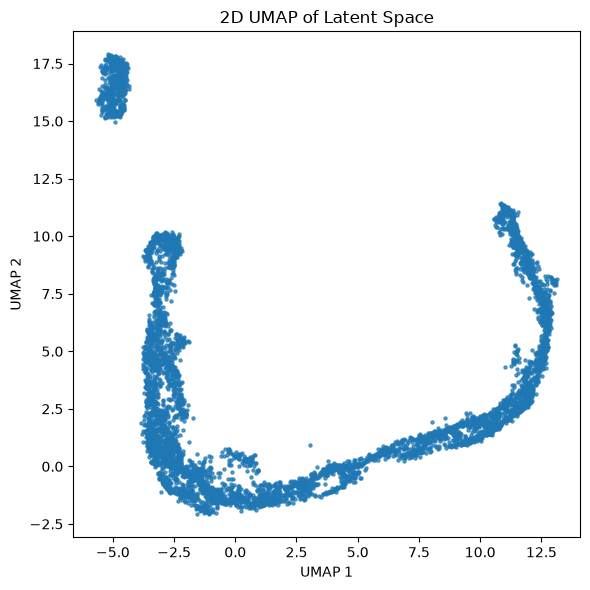

In [23]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(umap_embeddings[:, 0], umap_embeddings[:, 1], s=5, alpha=0.7)
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_title("2D UMAP of Latent Space")
plt.tight_layout()
plt.show()